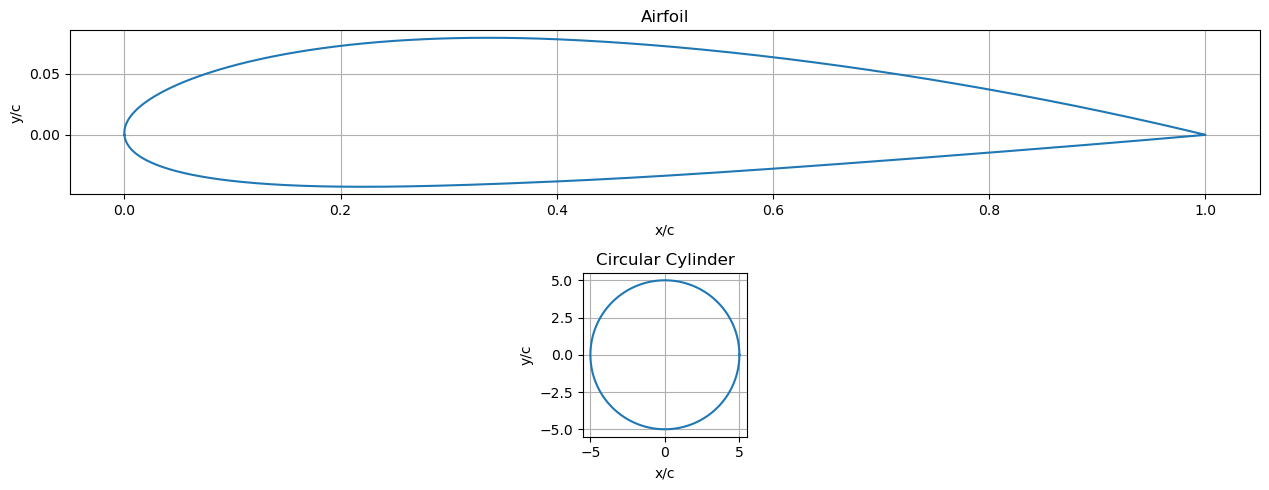

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Airfoil Plotting
a = 300
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100       
p = 4 / 10        
t = 12 / 100     

V_inf = 10
alpha = 0
alpha_rad = np.deg2rad(alpha)

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    if p == 0:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
            x_u[i] = x[i]  
            x_l[i] = x[i] 
            y_u[i] = y_t[i]
            y_l[i] = - y_t[i]
    else:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
        
            if 0 <= x[i] <= p:                      
                y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / p**2) * (p - x[i])
        
            elif p < x[i] <= 1:
                y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
                
            theta[i] = np.arctan(dyc_dx[i])         
            
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) 
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

    x_u[0], y_u[0] = 0, 0
    x_l[0], y_l[0] = 0, 0

    x_u[-1], y_u[-1] = 1, 0
    x_l[-1], y_l[-1] = 1, 0
    
    # Combine upper and lower surfaces
    x_full = np.concatenate((x_u, x_l[-2:0:-1], [x_l[0]]))
    y_full = np.concatenate((y_u, y_l[-2:0:-1], [y_l[0]]))

    return x_full, y_full
    
def circular_cylinder(N, R):
    theta = np.linspace(0, 2*np.pi, N+1)
    x = R*np.cos(theta)
    y = -R*np.sin(theta) 
    
    return x, y

f = airfoil_generation(x, m, p, t)

radius = 5
x_cylinder, y_cylinder = circular_cylinder(a, radius)

fig, ax = plt.subplots(2, 1, figsize=(13, 5))

ax[0].plot(f[0], f[1])
ax[0].set_xlabel("x/c")
ax[0].set_ylabel("y/c")
ax[0].set_title("Airfoil")
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder)
ax[1].set_xlabel("x/c")
ax[1].set_ylabel("y/c")
ax[1].set_title("Circular Cylinder")
ax[1].set_aspect('equal')
ax[1].grid(True)

plt.tight_layout()
plt.show()

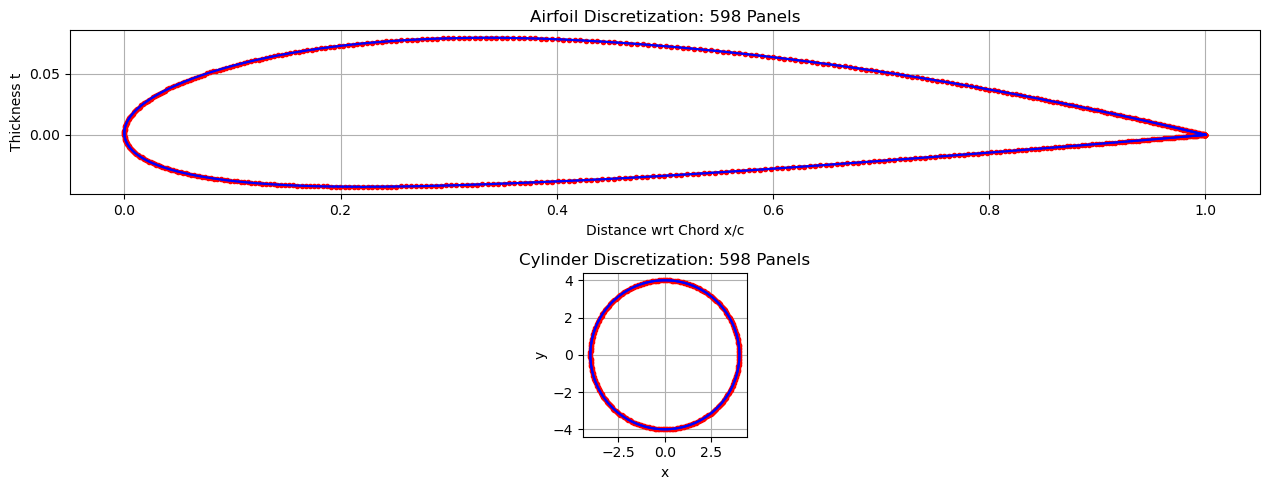

In [2]:
def panel_gen(x, y, V_inf, alpha_rad):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    theta_p = np.mod(theta_p, 2 * np.pi)

    theta_final = theta_p + np.pi / 2
    beta  = theta_final - alpha_rad

    V_normal = V_inf * np.cos(beta)
    V_tangent = V_inf * np.sin(beta)
    
    return N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent 

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_airfoil, y_airfoil, V_inf, alpha_rad)
N1, l1, x_c1, y_c2, theta_p1, x11, x21, y11, y21, V_normal1, V_tangent1 = panel_gen(x_cylinder, y_cylinder, V_inf, alpha_rad)

fig, ax = plt.subplots(2, 1, figsize=(13, 5))
ax[0].plot(x_airfoil, y_airfoil)
ax[0].plot(x_c, y_c1, 'ro', markersize=3)
for i in range(len(x1)):
    ax[0].plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
ax[0].set_xlabel("Distance wrt Chord x/c")
ax[0].set_ylabel("Thickness t")
ax[0].set_title(f'Airfoil Discretization: {N} Panels')
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder)
ax[1].plot(x_c1, y_c2, 'ro', markersize=3)
for i in range(len(x11)):
    ax[1].plot([x11[i], x21[i]], [y11[i], y21[i]], 'b-')
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title(f'Cylinder Discretization: {N} Panels')
ax[1].set_aspect('equal')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [3]:
def JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N, N))
    
    for i in range(N):
        tangent_vector0 = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])

        for j in range(N):
            if i == j:
                continue

            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]),np.sin(theta_p[j])])

            A = -np.dot(P_i - A_j, tangent_vector1)
            B = np.dot(P_i - A_j, P_i - A_j)
            Cn = -np.cos(theta_p[i] - theta_p[j])
            Ct = np.sin(theta_p[j] - theta_p[i])
            Dn = np.dot(P_i - A_j, tangent_vector0)
            Dt = ((P_i[0] - A_j[0]) * np.sin(theta_p[i]) - (P_i[1] - A_j[1]) * np.cos(theta_p[i]))
            E2 = B - A**2

            if E2 <= 1e-14:
                continue

            E = np.sqrt(E2)

            def dtheta_dn(s):
                n = (Cn * (A + s) + Dn - A * Cn) / ((A + s)**2 + E2)
                return n

            J[i, j] = quad(dtheta_dn, 0, l[j])[0]

    return J

def JK_linear(N, l, x_c, y_c1, theta_p, x1, y1):
    J1 = np.zeros((N, N+1))
    
    for i in range(N):
        for j in range(N):
            if i==j:
                J1[i, j] = J1[i, j] + 1
                J1[i, j+1] = J1[i, j + 1] - 1
                continue

            def dtheta_dn(s):
                xj = x1[j] + s*np.cos(theta_p[j])
                yj = y1[j] + s*np.sin(theta_p[j])

                dx = x_c[i] - xj
                dy = y_c1[i] - yj
                n = (dx*np.cos(theta_p[i]) + dy*np.sin(theta_p[i])) / (dx**2 + dy**2)
                return n
                
            def dtheta_linear(s):
                g = (s/l[j])*dtheta_dn(s)
                return g

            Jij = quad(dtheta_dn, 0, l[j])[0]
            Jpij = quad(dtheta_linear, 0, l[j])[0]
            J1[i, j] = J1[i, j] + Jij - Jpij
            J1[i, j+1] = J1[i, j+1] + Jpij

    return J1
    
J= JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)

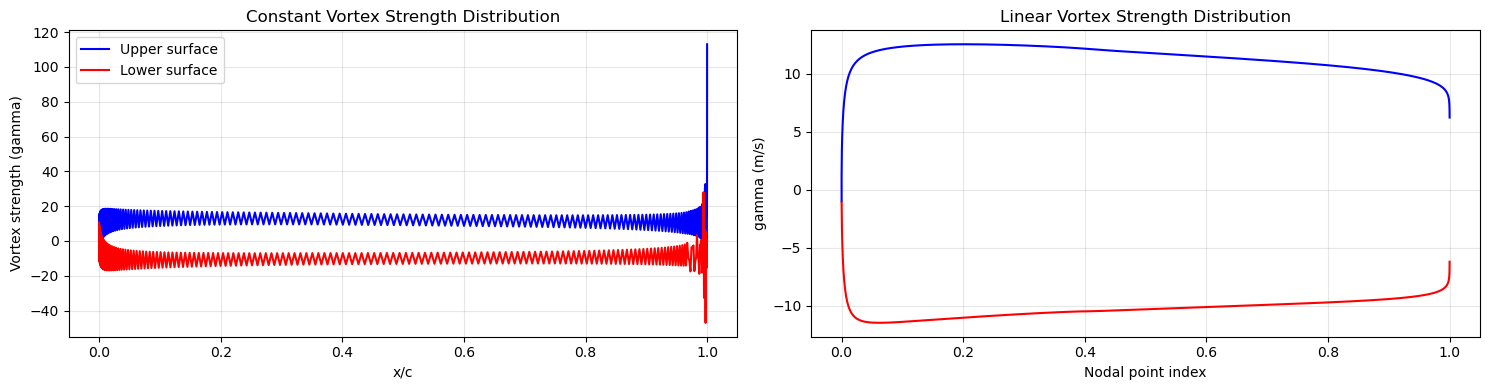

In [4]:
def vortex_panel_0(N, V_normal, J, l=None, kutta=True):
    A = J.copy()
    b = 2 * np.pi * V_normal

    if kutta:
        k = N // 2
        A[k, :] = 0
        A[k, k + 1] = 1
        A[k, k] = 1
        b[k] = 0
        gamma = np.linalg.solve(A, b)
        
    else:
        A = np.vstack([A, l])
        b = np.append(b, 0)
        gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    return gamma, A, b

def vortex_panel_method1(N, J1, V_normal, l=None, kutta=True):
    M = np.zeros((N+1, N+1))
    RHS = np.zeros(N+1)

    M[:N, :] = J1
    RHS[:N] = 2 * np.pi * V_normal

    if kutta:
        M[N, N//2] = 1       
        
    else:
        M[N, :N] += 0.5 * l        
        M[N, 1:] += 0.5 * l
    RHS[N] = 0

    gamma_nodes = np.linalg.solve(M, RHS)
    
    return gamma_nodes, M, RHS
    
gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)
x_nodes = np.append(x1, x1[-1] + l[-1]*np.cos(theta_p[-1]))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(x_c[:N//2], gamma[:N//2], 'b-', label='Upper surface')
ax[0].plot(x_c[N//2+1:], gamma[N//2+1:], 'r-', label='Lower surface')
ax[0].set_xlabel('x/c')
ax[0].set_ylabel('Vortex strength (gamma)')
ax[0].set_title('Constant Vortex Strength Distribution')
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(x_nodes[:N//2], gamma_nodes[:N//2], 'b-', label='Upper surface')
ax[1].plot(x_nodes[N//2+1:], gamma_nodes[N//2+1:], 'r-', label='Lower surface')
ax[1].set_xlabel('Nodal point index')
ax[1].set_ylabel('gamma (m/s)')
ax[1].set_title('Linear Vortex Strength Distribution')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The Coefficient of lift generated at 0 degrees by NACA 2412 by linear method is: 0.25962184422614953
The Coefficient of lift generated at 0 degrees by NACA 2412 by constant method is: 0.4550513377576877


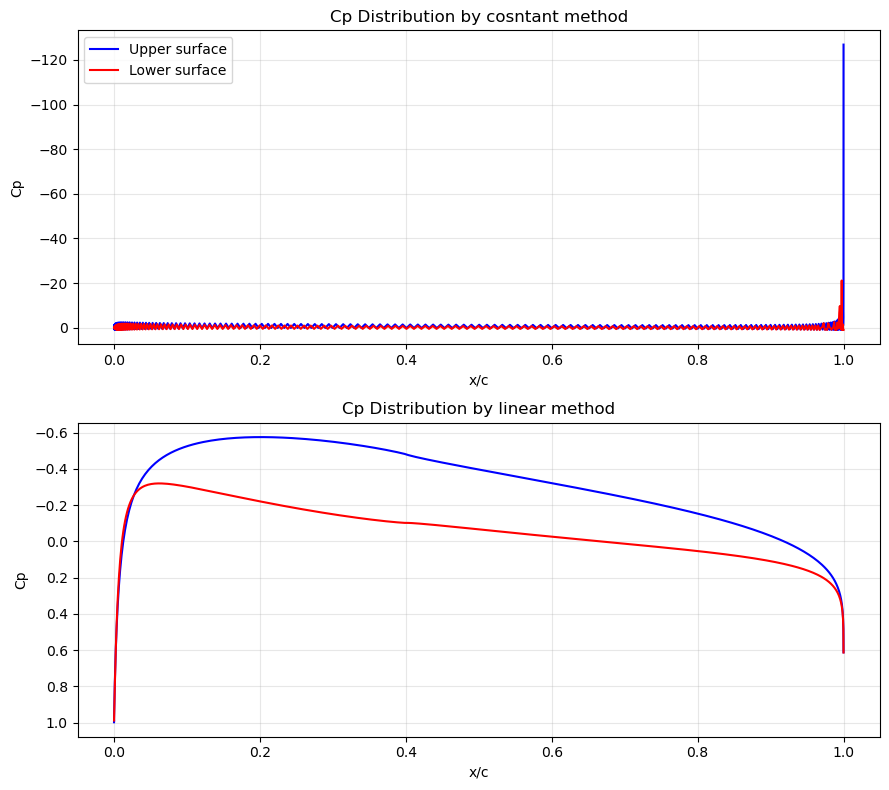

In [5]:
def pressure_coeff(gamma, V_inf):
    Cp = 1 - (gamma / V_inf)**2
    return Cp 

def lift_coeff(N, V_inf, gamma,gamma_nodes,  l):
    circulation = np.sum(0.5 * l * (gamma_nodes[:-1] + gamma_nodes[1:]))
    Cl_constant = 2 * np.sum(gamma * l) / V_inf
    total_circulation = np.sum(circulation)
    Cl = 2 * total_circulation / V_inf

    return Cl, Cl_constant

Cl = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[0]
Cl1 = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[1]
Cp = pressure_coeff(gamma, V_inf)
Cp1 = pressure_coeff(gamma_nodes, V_inf)

print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} by linear method is: {Cl}")
print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} by constant method is: {Cl1}")

fig, ax = plt.subplots(2, 1, figsize=(9, 8))
ax[0].plot(x_c[:N//2], Cp[:N//2], 'b-', label='Upper surface')
ax[0].plot(x_c[N//2+1:], Cp[N//2+1:], 'r-', label='Lower surface')
ax[0].set_xlabel('x/c')
ax[0].set_ylabel('Cp')
ax[0].set_title('Cp Distribution by cosntant method')
ax[0].invert_yaxis()
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(x_nodes[:N//2], Cp1[:N//2], 'b-', label='Upper surface')
ax[1].plot(x_nodes[N//2+1:], Cp1[N//2+1:], 'r-', label='Lower surface')
ax[1].set_xlabel('x/c')
ax[1].set_ylabel(r'Cp')
ax[1].invert_yaxis()
ax[1].set_title('Cp Distribution by linear method')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


NACA 0012
Points per surface: [20, 30, 40, 50]
Total number of panels: [38 58 78 98]
Reference Cl: 0.5483113556160755

Constant-strength method
Cl = [0.94930853 0.892329   0.8514993  0.8590179 ]
Error (%) = [73.13311554 62.7412953  55.29485014 56.66607908]

Linear-strength method
Cl = [0.60159273 0.60239816 0.6026731  0.60279832]
Error (%) = [9.71735722 9.86425061 9.91439319 9.93723032]

NACA 2412
Points per surface: [20, 30, 40, 50]
Total number of panels: [38 58 78 98]
Reference Cl: 0.7760798927389931

Constant-strength method
Cl = [1.26698841 0.9528039  0.98148641 0.97952896]
Error (%) = [63.25489402 22.77136794 26.46718681 26.21496432]

Linear-strength method
Cl = [0.85893074 0.86048748 0.86102483 0.86126932]
Error (%) = [10.6755569  10.87614603 10.94538624 10.97688897]


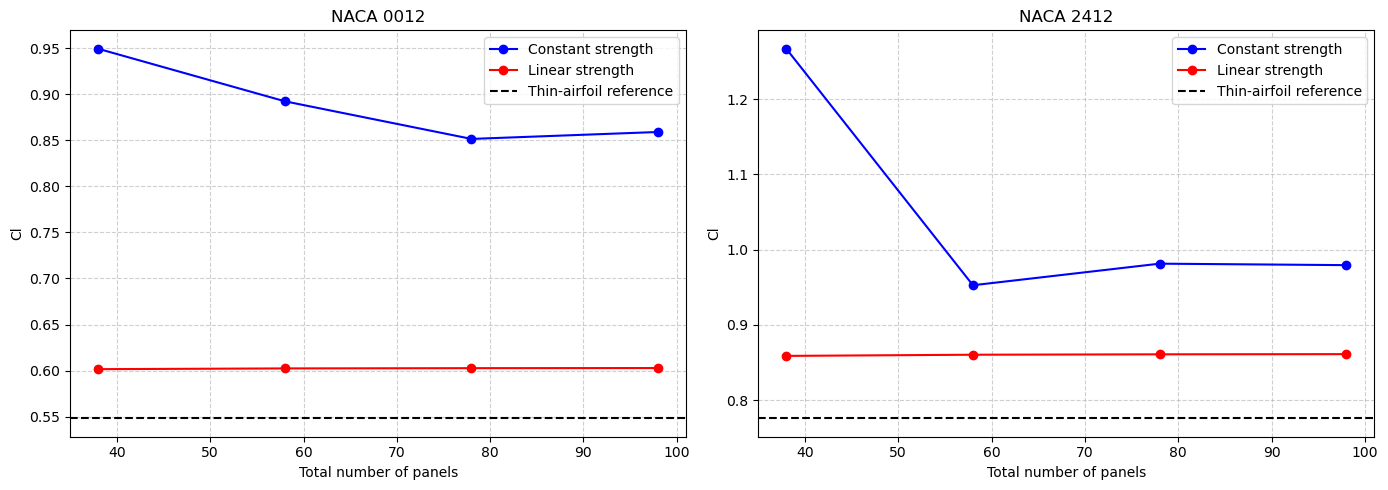

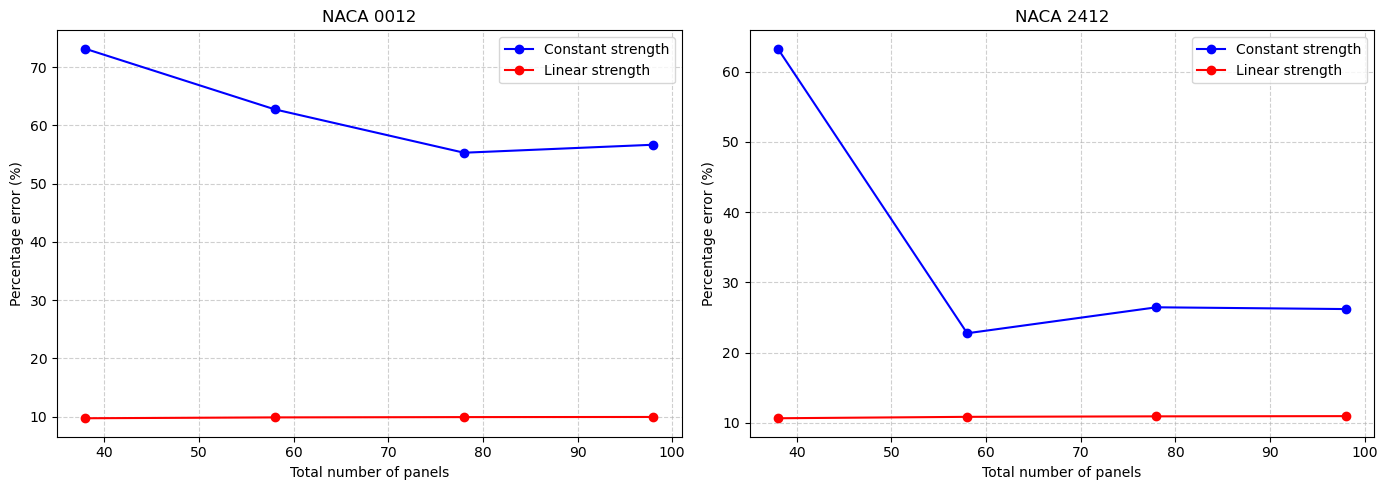


Final panel-count errors
NACA 0012
Constant-strength error: 56.666 %
Linear-strength error: 9.937 %
NACA 2412
Constant-strength error: 26.215 %
Linear-strength error: 10.977 %


In [6]:
# Compare the two methods for different panel resolutions

V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

# N_target is the number of cosine-spaced points on each surface.
N_points = [20, 30, 40, 50]
N_total = np.array([2 * (n - 1) for n in N_points])

m = [0/100, 2/100]
p = [0/10, 4/10]
t = [12/100, 12/100]

airfoil_names = ['NACA 0012', 'NACA 2412']

# Thin-airfoil-theory reference values at 5 degrees.
Cl_ref = [
    2*np.pi*np.deg2rad(alpha),
    2*np.pi*np.deg2rad(alpha + 2.077)
]

Cl = np.zeros((len(N_points), 2, 2))
Error = np.zeros_like(Cl)

for i, N_target in enumerate(N_points):
    beta = np.linspace(0, np.pi, N_target)
    x = 0.5 * (1 - np.cos(beta))

    for k in range(2):
        x_full, y_full = airfoil_generation(x, m[k], p[k], t[k])

        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(
            x_full, y_full, V_inf, alpha_rad
        )

        J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)

        J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma_nodes, M, RHS = vortex_panel_method1(
            N, J1, V_normal, l=None, kutta=True
        )

        Cl[i, k, 1], Cl[i, k, 0] = lift_coeff(
            N, V_inf, gamma, gamma_nodes, l
        )

        Error[i, k, :] = (
            np.abs(Cl[i, k, :] - Cl_ref[k]) / abs(Cl_ref[k]) * 100
        )

for k in range(2):
    print("\n====================================")
    print(airfoil_names[k])
    print("====================================")
    print("Points per surface:", N_points)
    print("Total number of panels:", N_total)
    print("Reference Cl:", Cl_ref[k])

    print("\nConstant-strength method")
    print("Cl =", Cl[:, k, 0])
    print("Error (%) =", Error[:, k, 0])

    print("\nLinear-strength method")
    print("Cl =", Cl[:, k, 1])
    print("Error (%) =", Error[:, k, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for k in range(2):
    ax[k].plot(N_total, Cl[:, k, 0], 'bo-', label='Constant strength')
    ax[k].plot(N_total, Cl[:, k, 1], 'ro-', label='Linear strength')
    ax[k].axhline(Cl_ref[k], color='black', linestyle='--',
                  label='Thin-airfoil reference')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Total number of panels')
    ax[k].set_ylabel('Cl')
    ax[k].grid(True, linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for k in range(2):
    ax[k].plot(N_total, Error[:, k, 0], 'bo-', label='Constant strength')
    ax[k].plot(N_total, Error[:, k, 1], 'ro-', label='Linear strength')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Total number of panels')
    ax[k].set_ylabel('Percentage error (%)')
    ax[k].grid(True, which='both', linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

print("\nFinal panel-count errors")
for k in range(2):
    print(airfoil_names[k])
    print("Constant-strength error:", round(Error[-1, k, 0], 3), "%")
    print("Linear-strength error:", round(Error[-1, k, 1], 3), "%")

In [7]:
alpha_rad1 = np.deg2rad(np.array([0, 3, 6, 9, 12]))
alpha_deg = np.rad2deg(alpha_rad1)

a1 = 60  # points on each surface for the angle study
beta = np.linspace(0, np.pi, a1)
x5 = 0.5 * (1 - np.cos(beta))
m = [0 / 100, 2/100]     
p = [0 / 10 , 4/10]       
t = [12 / 100, 12/100] 

Cl = np.zeros((2, len(alpha_rad1), 2))
Cm = np.zeros((2, len(alpha_rad1), 2))
Cp = np.zeros((2, len(alpha_rad1), 2*a1 - 1))

n_airfoils = len(m)
n_alpha = len(alpha_deg)

n_nodes = 2*a1 - 1
n_panels = n_nodes - 1  # total panels = 2*(a1 - 1)

Cl = np.zeros((n_airfoils, n_alpha, 2))
Cm = np.zeros((n_airfoils, n_alpha, 2))
Cp = np.zeros((n_airfoils, n_alpha, n_nodes))

Xc = np.zeros((n_airfoils, n_nodes))

for i in range(n_airfoils):
    x_full, y_full = airfoil_generation(x5, m[i], p[i], t[i])
    Xc[i, :] = x_full
    for j in range(n_alpha):
        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_full, y_full, V_inf, alpha_rad1[j])
        J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
        gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)
        Cl[i, j, 1],Cl[i, j, 0] = lift_coeff(N, V_inf, gamma,gamma_nodes, l)
        Cm[i, j, 0] = - Cl[i, j, 0] / 4
        Cm[i, j, 1] = - Cl[i, j, 1] / 4
        Cp[i, j, :] = pressure_coeff(gamma_nodes, V_inf)

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Asymmetric airfoil - Constant:", Cl[1, :, 0])
print("Asymmetric airfoil - Linear:", Cl[1, :, 1])

Symmetric airfoil - Constant: [1.36291556 1.72483822 2.08203323 2.43352152 2.7783397 ]
Symmetric airfoil - Linear: [4.59597638e-15 3.62013390e-01 7.23034526e-01 1.08207387e+00
 1.43814733e+00]
Asymmetric airfoil - Constant: [0.52923534 0.80201112 1.07258865 1.34022628 1.60419045]
Asymmetric airfoil - Linear: [0.25948471 0.62116518 0.98114308 1.33843174 1.69205184]


NACA 0012 - Thin Airfoil Theory: [0.         0.32898681 0.65797363 0.98696044 1.31594725]
NACA 2412 - Thin Airfoil Theory: [0.22776854 0.55675535 0.88574216 1.21472898 1.54371579]
Symmetric airfoil - Constant: [1.36291556 1.72483822 2.08203323 2.43352152 2.7783397 ]
Symmetric airfoil - Linear: [4.59597638e-15 3.62013390e-01 7.23034526e-01 1.08207387e+00
 1.43814733e+00]
Cambered airfoil - Constant: [0.52923534 0.80201112 1.07258865 1.34022628 1.60419045]
Cambered airfoil - Linear: [0.25948471 0.62116518 0.98114308 1.33843174 1.69205184]


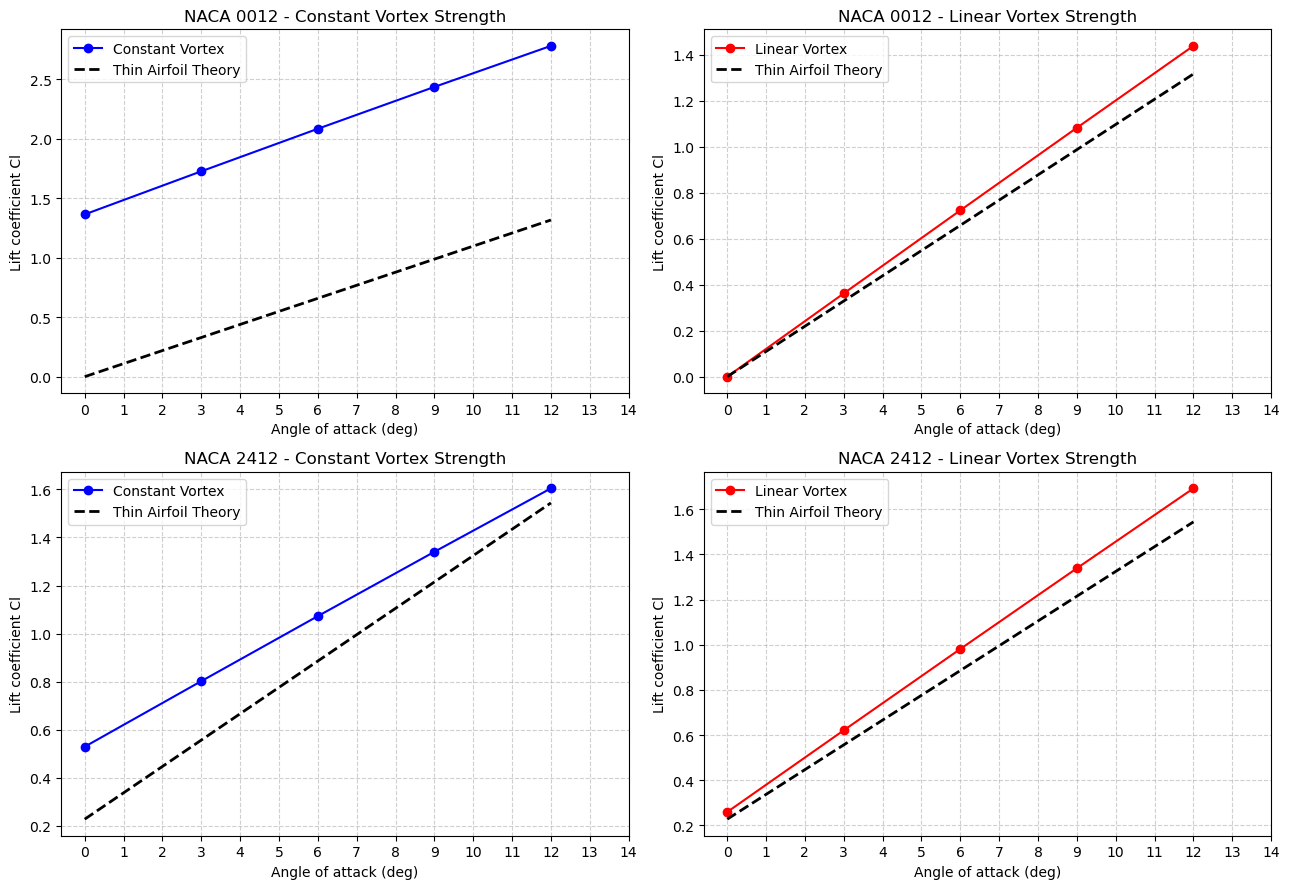

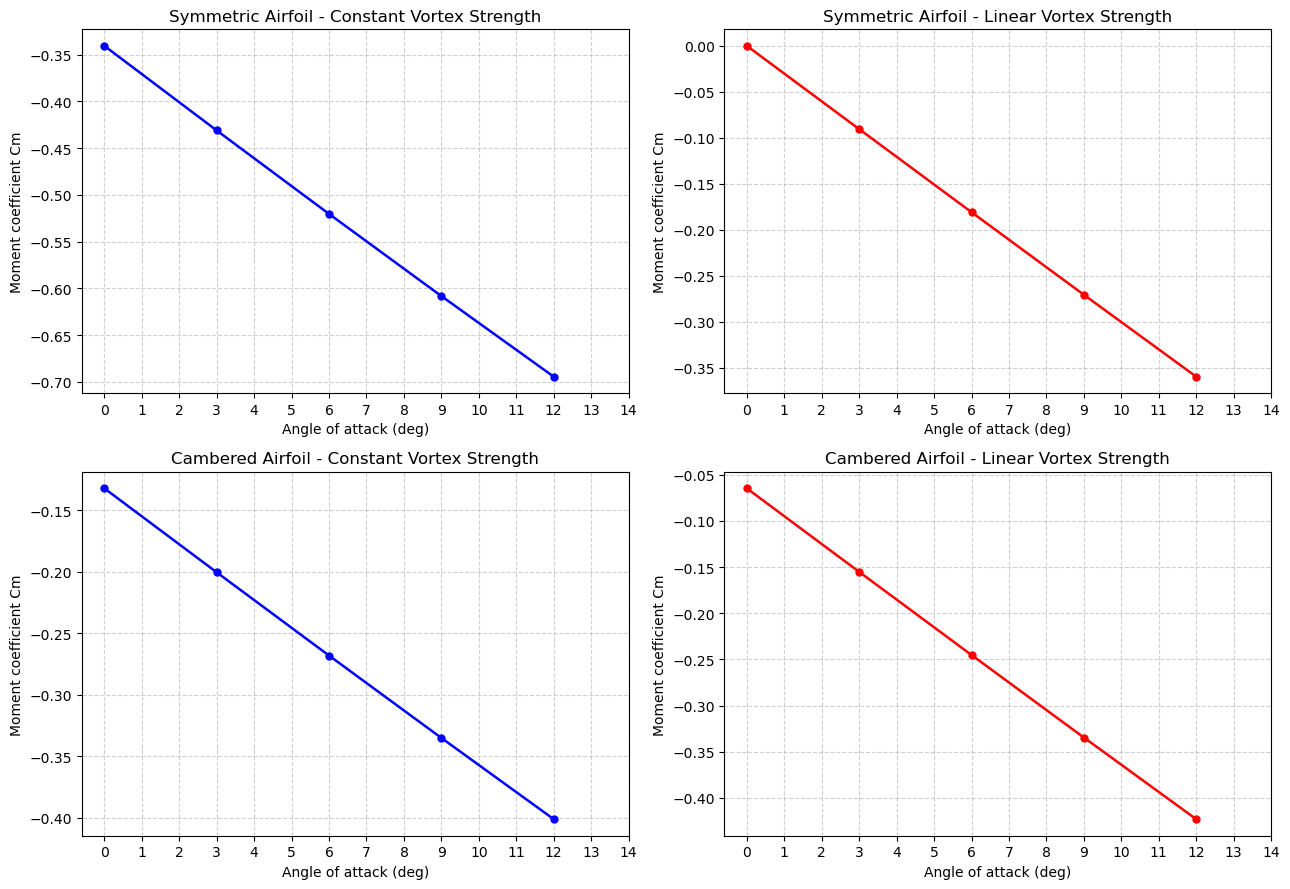

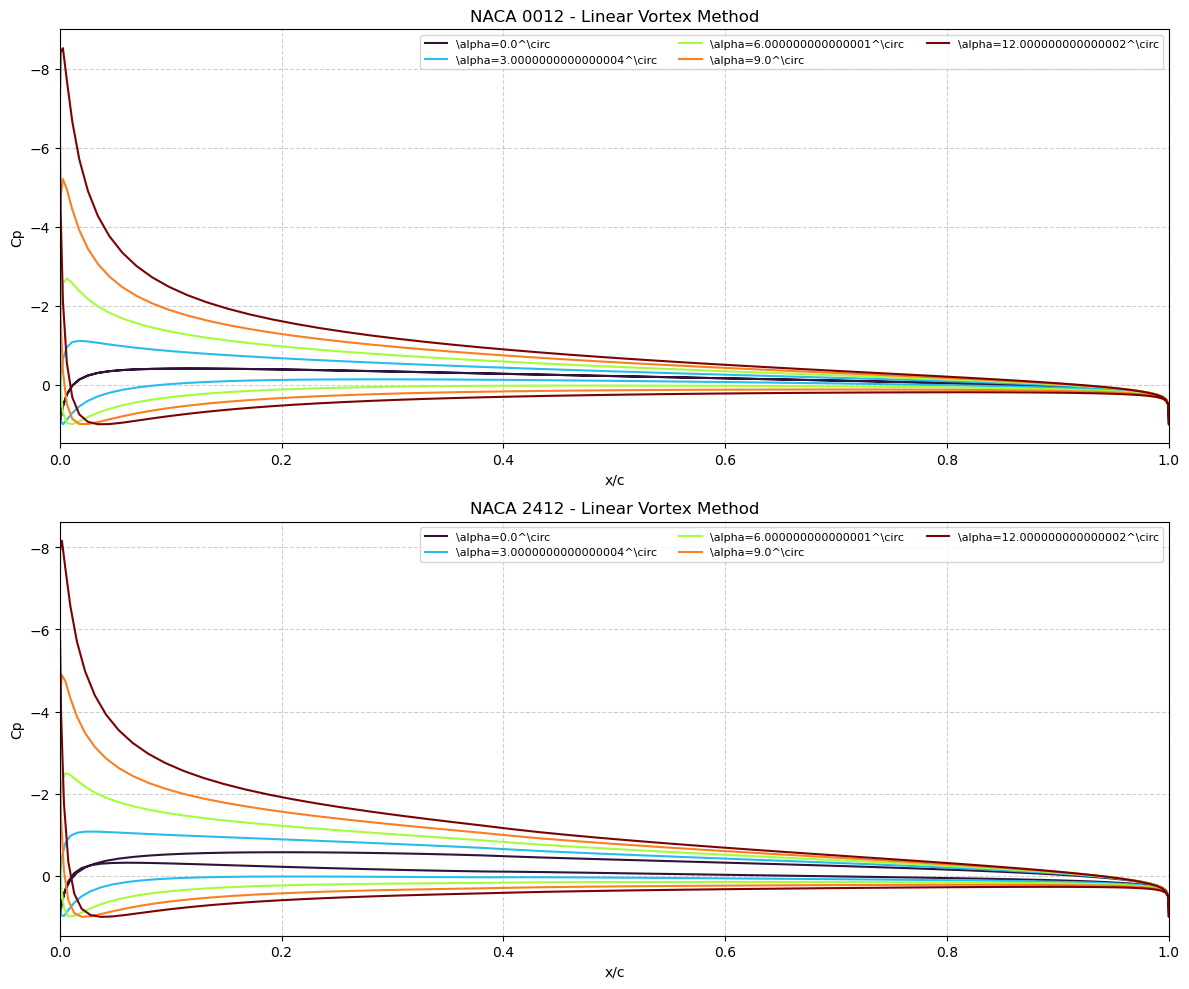

In [8]:
Cl_exact = np.zeros((2, n_alpha))

Cl_exact[0, :] = 2 * np.pi * np.deg2rad(alpha_deg)
Cl_exact[1, :] = 2 * np.pi * np.deg2rad(alpha_deg + 2.077)

print("NACA 0012 - Thin Airfoil Theory:", Cl_exact[0, :])
print("NACA 2412 - Thin Airfoil Theory:", Cl_exact[1, :])

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Cambered airfoil - Constant:", Cl[1, :, 0])
print("Cambered airfoil - Linear:", Cl[1, :, 1])

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].plot(alpha_deg, Cl[0, :, 0], 'bo-', label='Constant Vortex')
ax[0, 0].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 0].set_title('NACA 0012 - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cl[0, :, 1], 'ro-', label='Linear Vortex')
ax[0, 1].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 1].set_title('NACA 0012 - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cl[1, :, 0], 'bo-', label='Constant Vortex')
ax[1, 0].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 0].set_title('NACA 2412 - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cl[1, :, 1], 'ro-', label='Linear Vortex')
ax[1, 1].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 1].set_title('NACA 2412 - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel('Angle of attack (deg)')
    a.set_ylabel('Lift coefficient Cl')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(alpha_deg, Cm[0, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[0, 0].set_title('Symmetric Airfoil - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cm[0, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[0, 1].set_title('Symmetric Airfoil - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cm[1, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[1, 0].set_title('Cambered Airfoil - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cm[1, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[1, 1].set_title('Cambered Airfoil - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel('Angle of attack (deg)')
    a.set_ylabel('Moment coefficient Cm')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(12, 10))
colors = plt.cm.turbo(np.linspace(0, 1, n_alpha))

for j in range(n_alpha):
    ax[0].plot(Xc[0, :], Cp[0, j, :], color=colors[j],
               linewidth=1.5, label=fr'\alpha={alpha_deg[j]}^\circ')

    ax[1].plot(Xc[1, :], Cp[1, j, :], color=colors[j],
               linewidth=1.5, label=fr'\alpha={alpha_deg[j]}^\circ')

ax[0].set_title('NACA 0012 - Linear Vortex Method')
ax[1].set_title('NACA 2412 - Linear Vortex Method')

for a in ax:
    a.set_xlabel('x/c')
    a.set_ylabel('Cp')
    a.set_xlim(0, 1)
    a.invert_yaxis()
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend(ncol=3, fontsize=8, loc='best')

plt.tight_layout()
plt.show()

Thickness (%) [12, 18, 24, 30]
Constant-strength Cl: [1.96355425 0.13467367 0.38911771 0.35147589]
Linear-strength Cl: [0.60286557 0.63093249 0.65928894 0.68794075]
Constant-strength error (%): [258.11677025  75.4379595   29.0319693   35.89715749]
Linear-strength error (%): [ 9.95177192 15.07067082 20.24237527 25.46794549]


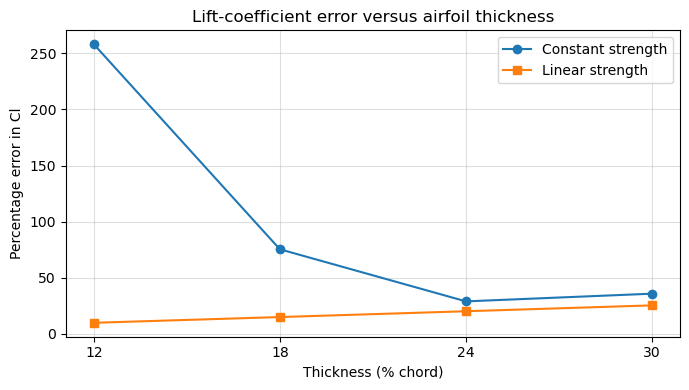

In [9]:
# Effect of thickness for symmetric NACA airfoils

Cl_exact = 0.5483
V_inf = 10
alpha_rad = np.deg2rad(5)

a = 60
beta = np.linspace(0, np.pi, a)
x5 = 0.5 * (1 - np.cos(beta))

# Symmetric sections: zero camber and zero camber position.
m_thickness = 0
p_thickness = 0
thickness = [12, 18, 24, 30]
t_values = [value / 100 for value in thickness]

Cl = np.zeros((len(t_values), 2))

for i, t1 in enumerate(t_values):
    x_airfoil, y_airfoil = airfoil_generation(
        x5, m_thickness, p_thickness, t1
    )

    N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(
        x_airfoil, y_airfoil, V_inf, alpha_rad
    )

    J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
    J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)

    gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
    gamma_nodes, M, RHS = vortex_panel_method1(
        N, J1, V_normal, l=None, kutta=True
    )

    Cl[i, 1], Cl[i, 0] = lift_coeff(N, V_inf, gamma, gamma_nodes, l)

error_constant = np.abs(Cl_exact - Cl[:, 0])
error_linear = np.abs(Cl_exact - Cl[:, 1])

error_percent_constant = error_constant / abs(Cl_exact) * 100
error_percent_linear = error_linear / abs(Cl_exact) * 100

print("Thickness (%)", thickness)
print("Constant-strength Cl:", Cl[:, 0])
print("Linear-strength Cl:", Cl[:, 1])
print("Constant-strength error (%):", error_percent_constant)
print("Linear-strength error (%):", error_percent_linear)

plt.figure(figsize=(7, 4))
plt.plot(thickness, error_percent_constant, 'o-', label='Constant strength')
plt.plot(thickness, error_percent_linear, 's-', label='Linear strength')
plt.xlabel('Thickness (% chord)')
plt.ylabel('Percentage error in Cl')
plt.title('Lift-coefficient error versus airfoil thickness')
plt.xticks(thickness)
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

Cl (linear):   [-1.70530257e-15  6.25277607e-15  8.66862138e-15 -1.81188398e-15
 -7.06990022e-15 -1.39444012e-14 -7.44293516e-15 -1.32782674e-14
  2.28084218e-14 -1.32693856e-14 -4.92494934e-15 -7.26085858e-15
  4.54747351e-15 -1.36424205e-14 -2.72848411e-14]
Cl (constant): [ 1.70530257e-15  5.13011855e-14 -1.06581410e-15  3.94351218e-15
 -5.75539616e-15  5.08038056e-15 -1.42463819e-14  9.45021839e-15
  3.07887049e-14  2.12496687e-14 -2.19912977e-14  9.28146449e-16
  2.27373675e-14 -9.09494702e-15  1.36424205e-14]


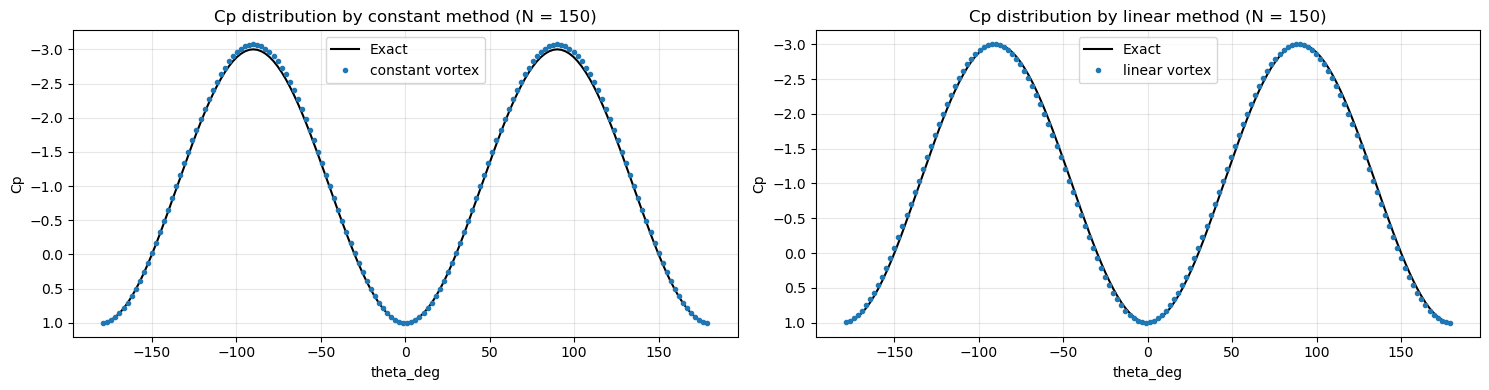

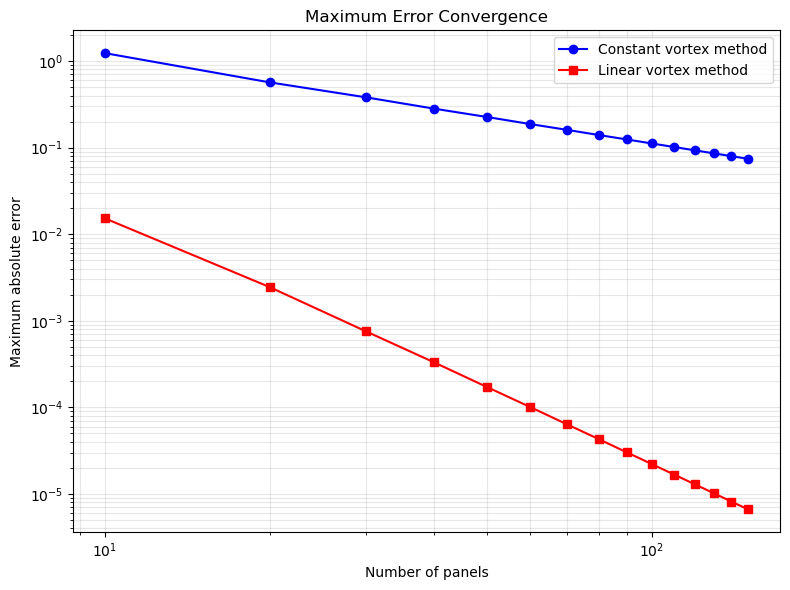

In [10]:
#Circular Cylinder 
panels = np.arange(10, 151, 10)          
radius = 4
alpha_rad = 0
V_inf = 100

Cl = np.zeros(len(panels))
Cl1 = np.zeros(len(panels))
Cp, Cp1, Cp_exact, Cp_exact1, theta_list , theta_list1 = [], [], [], [], [], []
Max_Error = np.zeros((len(panels), 2))

for i, n in enumerate(panels):
    x_cylinder, y_cylinder = circular_cylinder(n, radius)
    N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_cylinder, y_cylinder, V_inf, alpha_rad)
    J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
    J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
    gamma, A, b = vortex_panel_0(N, V_normal, J, l=l, kutta=False)
    gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=l, kutta=False)

    Cl[i], Cl1[i] = lift_coeff(N, V_inf, gamma, gamma_nodes, l)

    Cp_i  = pressure_coeff(gamma, V_inf)
    Cp1_i = pressure_coeff(gamma_nodes, V_inf)

    theta_c = np.arctan2(y_c1, x_c) 
    theta_c1 = np.arctan2(y_cylinder, x_cylinder)
    Cp_ex = 1 - 4*np.sin(theta_c - alpha_rad)**2         
    Cp_ex1 = 1 - 4*np.sin(theta_c1 - alpha_rad)**2
    
    Cp.append(Cp_i); Cp1.append(Cp1_i)
    Cp_exact.append(Cp_ex); theta_list.append(theta_c)
    Cp_exact1.append(Cp_ex1); theta_list1.append(theta_c1)

    Max_Error[i, 0] = np.max(np.abs(Cp_i  - Cp_ex))
    Max_Error[i, 1] = np.max(np.abs(Cp1_i - Cp_ex1))

print("Cl (linear):  ", Cl)
print("Cl (constant):", Cl1)

theta_deg = np.rad2deg(theta_list[-1])
order = np.argsort(theta_deg)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for axi, Cp_k, title in zip(ax, [Cp[-1], Cp1[-1]], ['constant', 'linear']):
    axi.plot(theta_deg[order], Cp_exact[-1][order], 'k-', label='Exact')
    axi.plot(theta_deg[order], Cp_k[order], 'o', ms=3, label=f'{title} vortex')
    axi.set_xlabel('theta_deg'); axi.set_ylabel('Cp')
    axi.set_title(f'Cp distribution by {title} method (N = {panels[-1]})')
    axi.invert_yaxis(); axi.grid(True, alpha=0.3); axi.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.loglog(panels, Max_Error[:, 0], 'bo-', label='Constant vortex method')
plt.loglog(panels, Max_Error[:, 1], 'rs-', label='Linear vortex method')
plt.xlabel('Number of panels')
plt.ylabel('Maximum absolute error')
plt.title('Maximum Error Convergence')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()